# Case iFood · Parte 2: segmentação de clientes

**Autor:** Victor Maurício · **Notebook 2 de 3** ·
[← Parte 1: análise exploratória](01_eda_e_tratamento.ipynb) ·
[Parte 3: modelo de propensão e lucro →](03_modelo_propensao_e_lucro.ipynb)

## 1. Objetivo e abordagem

O segundo entregável do case é **criar e descrever uma segmentação dos clientes com base no comportamento**.
Usamos **clusterização**, uma técnica de aprendizado não supervisionado: não existe um rótulo "certo" a prever;
o algoritmo agrupa os clientes pela semelhança entre suas características.

O algoritmo escolhido é o **K-Means**. Ele posiciona *k* centroides, atribui cada cliente ao centroide mais
próximo (distância euclidiana), recalcula os centroides como a média dos clientes de cada grupo e repete até
os grupos se estabilizarem.

**Por que o pré-processamento é essencial:** como o K-Means trabalha com distâncias, colunas com escalas maiores
dominariam o resultado. Sem tratamento, a renda (dezenas de milhares) pesaria muito mais que o número de filhos
(0 a 2), e os poucos clientes com gastos extremos puxariam os centroides. Por isso cada tipo de coluna recebe
uma transformação adequada antes do agrupamento (seção 3).

**A variável `Response` fica fora da segmentação.** Ela é o alvo do modelo da Parte 3. Se entrasse na
clusterização, o rótulo do cluster carregaria informação da resposta, e usar esse rótulo no modelo seria
vazamento de dados (*data leakage*). Além disso, a segmentação precisa poder ser aplicada a clientes que
ainda não foram contatados, para os quais a resposta não existe.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from matplotlib.ticker import PercentFormatter
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, PowerTransformer, StandardScaler

from src.config import CUSTO_CONTATO, DADOS_CLUSTERIZADOS, DADOS_TRATADOS, RANDOM_STATE, RECEITA_ACEITE
from src.graficos import (
    plot_clusters_2d,
    plot_cotovelo_silhueta,
    plot_percentual_cluster_por_coluna,
    plot_percentual_por_cluster,
    salvar_figura,
)

sns.set_theme(style="whitegrid", palette="tab10")

## 2. Dados

Usamos a base tratada na [Parte 1](01_eda_e_tratamento.ipynb): 2.023 clientes, sem duplicatas, valores ausentes
ou registros inválidos, e com as variáveis criadas na engenharia de features.

In [2]:
df = pd.read_parquet(DADOS_TRATADOS)

X = df.drop(columns="Response")

print(f"{X.shape[0]} clientes e {X.shape[1]} colunas usadas na segmentação")
X.head()

2023 clientes e 34 colunas usadas na segmentação


,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,YearsSinceEnrolled,Age,AgeGroup,MntTotal,MntRegularProds,Children,HasChildren,AcceptedCmpTotal,HasAcceptedCmp,NumTotalPurchases
ID,,,,,,,,,,,,,,,,,,,,,
5524,Graduation,Single,58138.0,0,0,58,635,88,546,172,...,1,57,46-60,1617,1529,0,0,0,0,22
2174,Graduation,Single,46344.0,1,1,38,11,1,6,2,...,0,60,46-60,27,21,2,1,0,0,4
4141,Graduation,Partner,71613.0,0,0,26,426,49,127,111,...,0,49,46-60,776,734,0,0,0,0,20
6182,Graduation,Partner,26646.0,1,0,26,11,4,20,10,...,0,30,18-30,53,48,1,1,0,0,6
5324,PhD,Partner,58293.0,1,0,94,173,43,118,46,...,0,33,31-45,422,407,1,1,0,0,14


## 3. Escolha das transformações

A transformação de cada coluna depende do tipo e da distribuição dela.

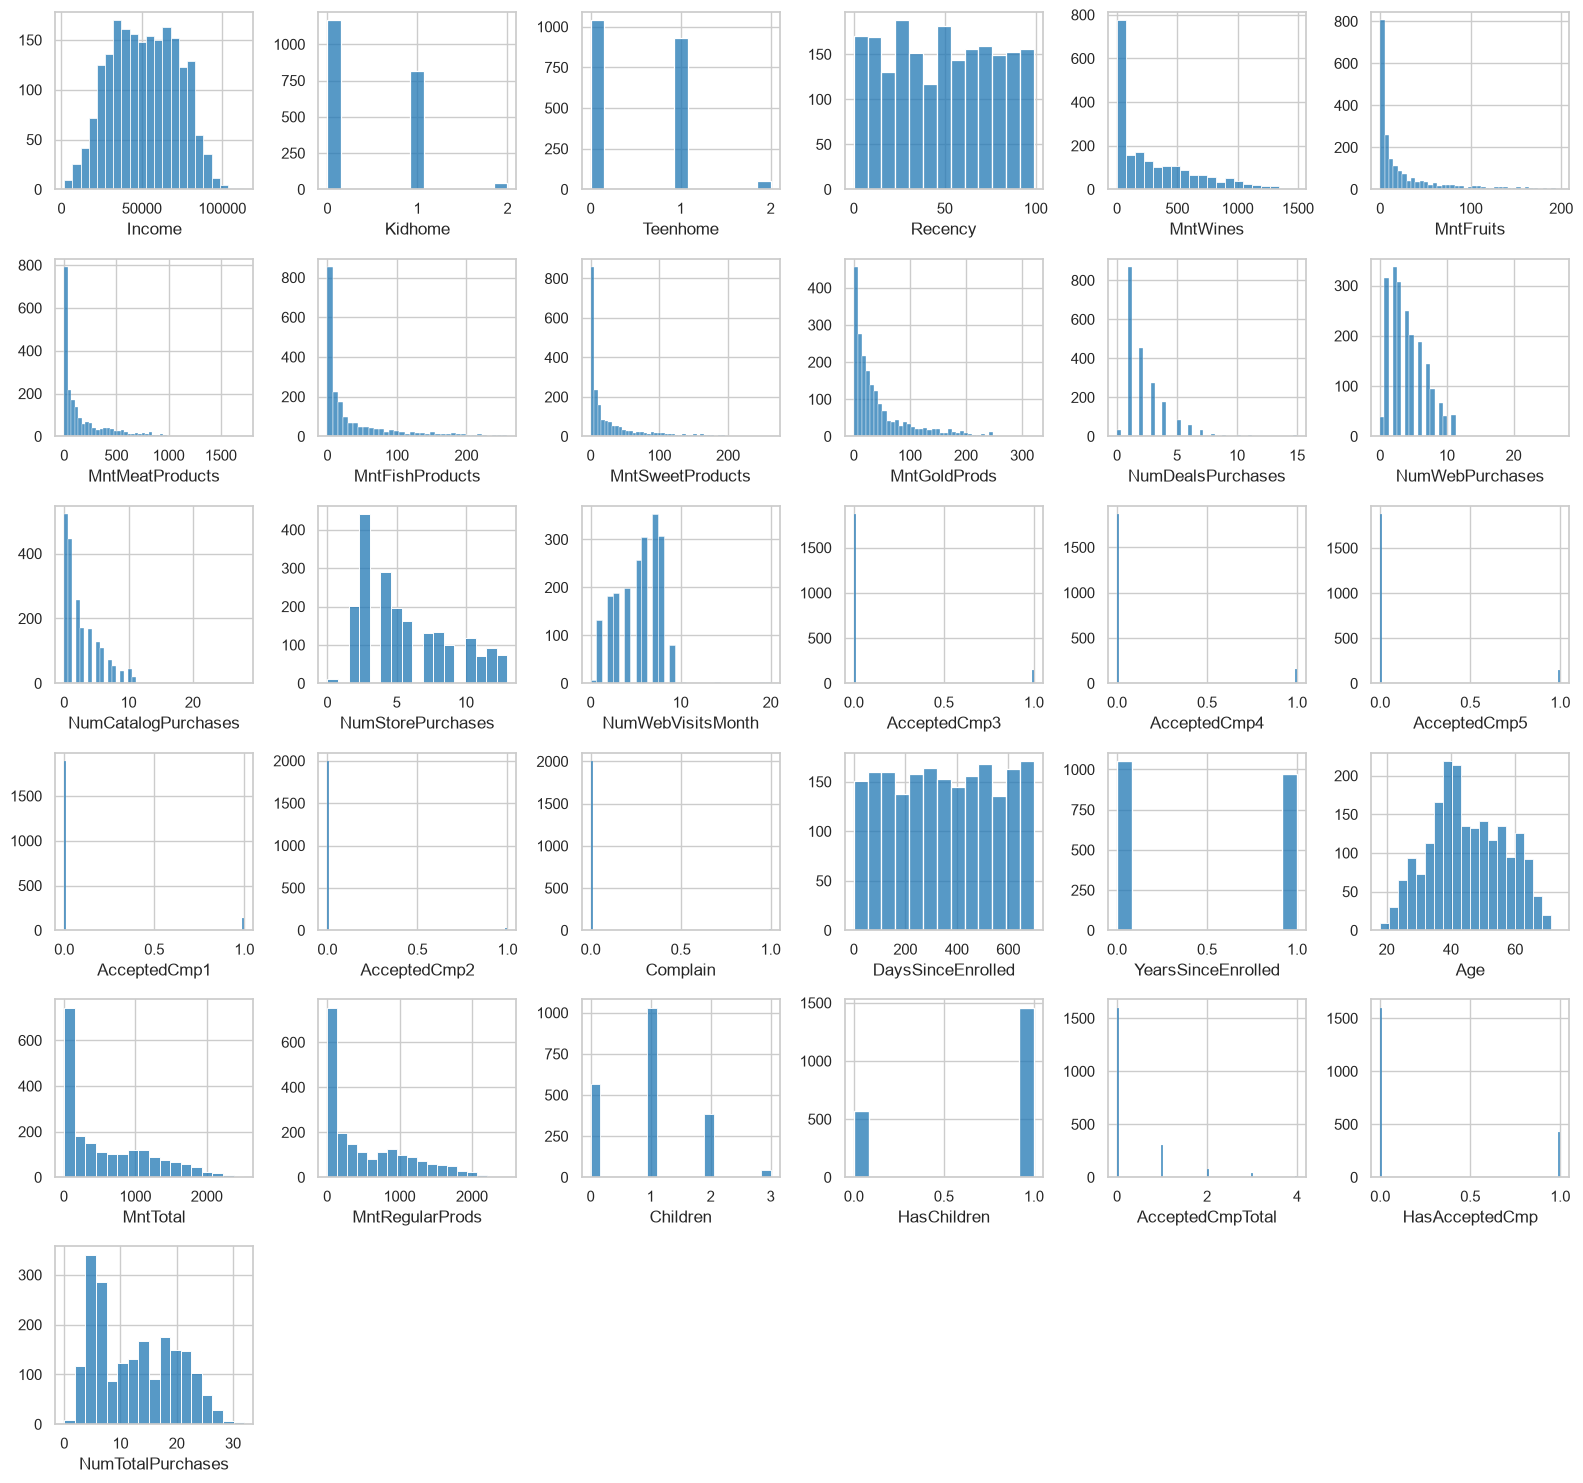

In [3]:
colunas_numericas = X.select_dtypes("number").columns

fig, axs = plt.subplots(6, 6, figsize=(16, 15))

for ax, coluna in zip(axs.flatten(), colunas_numericas):
    sns.histplot(data=X, x=coluna, ax=ax)
    ax.set_ylabel("")

for ax in axs.flatten()[len(colunas_numericas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

| Transformação | Colunas | Motivo |
|---|---|---|
| `OneHotEncoder` | `Education`, `Marital_Status`, `AgeGroup`, `Kidhome`, `Teenhome`, `Children`, `HasChildren`, `AcceptedCmp1` a `5`, `AcceptedCmpTotal`, `HasAcceptedCmp`, `Complain`, `YearsSinceEnrolled` | Variáveis categóricas ou discretas com poucos valores. O one-hot cria uma coluna binária por categoria e evita supor uma distância entre categorias que não existe (por exemplo, que "PhD" está "duas vezes mais longe" de "Basic" que "Master") |
| `StandardScaler` | `Income`, `Age` | Distribuição próxima da normal: basta centralizar em zero e dividir pelo desvio padrão |
| `PowerTransformer` (Yeo-Johnson) | Gastos (`Mnt*`) e compras (`Num*`) | Distribuições muito assimétricas, com muitos valores baixos e poucos muito altos. A transformação de potência as aproxima de uma normal e depois padroniza |
| `MinMaxScaler` | `Recency`, `DaysSinceEnrolled` | Distribuição aproximadamente uniforme: basta levar ao intervalo de 0 a 1 |

In [4]:
colunas_one_hot = [
    "Education",
    "Marital_Status",
    "AgeGroup",
    "Kidhome",
    "Teenhome",
    "Children",
    "HasChildren",
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "AcceptedCmpTotal",
    "HasAcceptedCmp",
    "Complain",
    "YearsSinceEnrolled",
]

colunas_standard = ["Income", "Age"]

colunas_power = X.columns[X.columns.str.startswith(("Mnt", "Num"))].tolist()

colunas_minmax = [
    coluna for coluna in X.columns
    if coluna not in colunas_one_hot + colunas_standard + colunas_power
]

print("MinMaxScaler:", colunas_minmax)

preprocessamento = ColumnTransformer(
    [
        ("one_hot", OneHotEncoder(), colunas_one_hot),
        ("standard", StandardScaler(), colunas_standard),
        ("minmax", MinMaxScaler(), colunas_minmax),
        ("power", PowerTransformer(), colunas_power),
    ]
)

X_transformado = pd.DataFrame(
    preprocessamento.fit_transform(X),
    columns=preprocessamento.get_feature_names_out(),
    index=X.index,
)

print(f"{X_transformado.shape[1]} colunas após o pré-processamento")

MinMaxScaler: ['Recency', 'DaysSinceEnrolled']


62 colunas após o pré-processamento


## 4. Efeito das transformações

Comparando as distribuições depois do pré-processamento (as colunas do one-hot ficam de fora porque só têm 0 e 1 como valores):

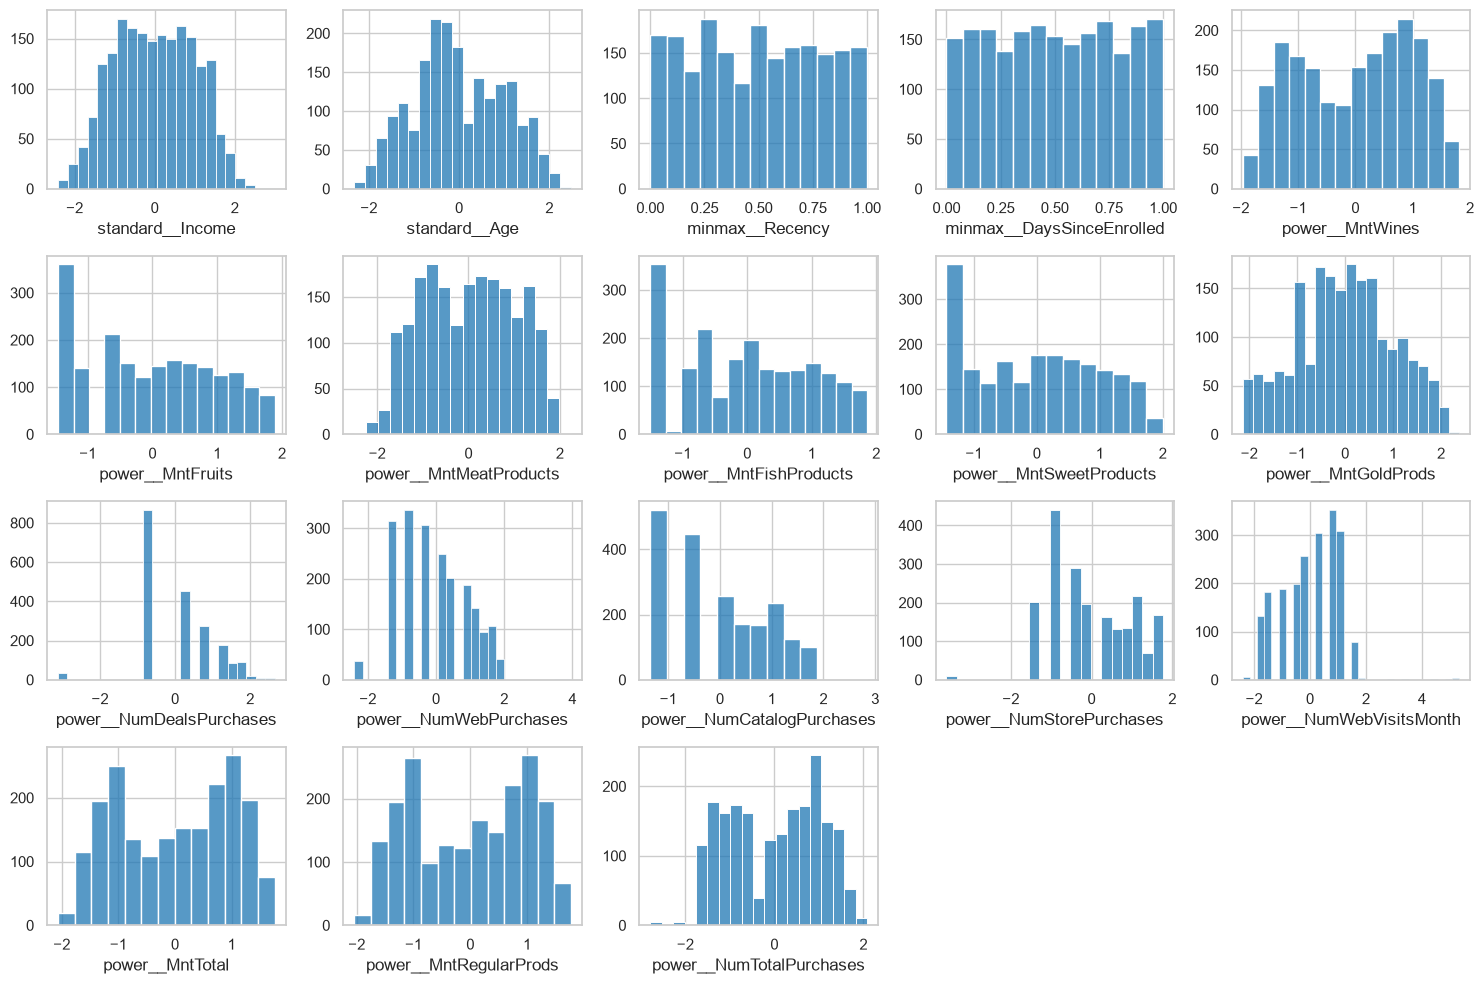

In [5]:
colunas_continuas = X_transformado.columns[~X_transformado.columns.str.startswith("one_hot")]

fig, axs = plt.subplots(4, 5, figsize=(15, 10))

for ax, coluna in zip(axs.flatten(), colunas_continuas):
    sns.histplot(data=X_transformado, x=coluna, ax=ax)
    ax.set_ylabel("")

for ax in axs.flatten()[len(colunas_continuas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

- **`Income` e `Age` mantêm o formato**, agora centralizadas em zero e com desvio padrão 1. O `StandardScaler`
  só desloca e muda a escala, não altera a forma da distribuição.
- **Gastos e compras ficaram muito mais simétricos.** Antes concentrados perto de zero com uma cauda longa, agora
  têm formato próximo de um sino, e os clientes de gasto extremo deixam de dominar as distâncias. Algumas colunas
  ainda mostram um pico isolado: são os muitos clientes com o mesmo valor (por exemplo, zero compras por catálogo),
  que nenhuma transformação consegue separar.
- **`Recency` e `DaysSinceEnrolled` continuam uniformes**, agora entre 0 e 1.

Todas as colunas contínuas passaram a ter ordem de grandeza parecida, o que é o objetivo para o K-Means.

## 5. Quantos clusters?

O K-Means exige que o número de clusters (*k*) seja definido antes. Usamos dois métodos:

- **Método do cotovelo:** a inércia é a soma das distâncias ao quadrado de cada cliente até o centroide do seu
  cluster. Ela sempre cai quando *k* aumenta; procuramos o ponto em que o ganho passa a ser pequeno (o "cotovelo").
- **Método da silhueta:** para cada cliente, compara a distância média aos clientes do próprio cluster (*a*) com
  a distância média aos do cluster vizinho mais próximo (*b*): *s* = (*b* − *a*) / max(*a*, *b*). O valor vai
  de −1 a 1, e quanto maior, mais bem separados estão os clusters.

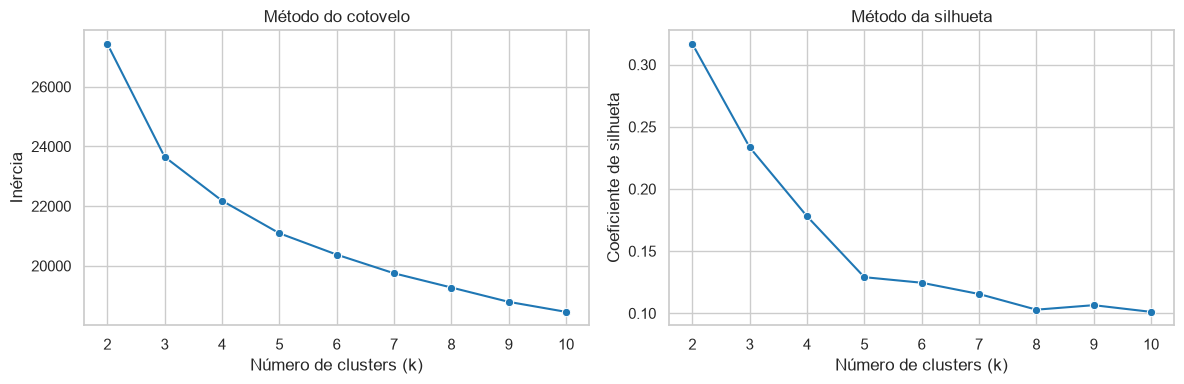

In [6]:
plot_cotovelo_silhueta(X_transformado, nome_arquivo="cotovelo_silhueta.png")

A silhueta é máxima com **k = 2**, mas dois grupos dariam uma divisão óbvia (clientes de renda alta e de renda
baixa) e pouco útil para o marketing. O cotovelo fica em **k = 3**: a partir daí, cada cluster adicional reduz
pouco a inércia, e a silhueta continua razoável. Os métodos são um guia, não uma regra; a escolha final considera
também se os grupos são interpretáveis e acionáveis. **Escolhemos k = 3.**

## 6. K-Means com 3 clusters

O pipeline junta o pré-processamento e o K-Means, para que a mesma transformação seja aplicada a qualquer
cliente novo. O parâmetro `n_init=10` roda o algoritmo com 10 inicializações diferentes e fica com a melhor.

In [7]:
pipeline_clusters = Pipeline(
    [
        ("preprocessamento", preprocessamento),
        ("clustering", KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)),
    ]
)

pipeline_clusters.fit(X)

df_clusters = df.copy()
df_clusters["Cluster"] = pipeline_clusters["clustering"].labels_

# o K-Means numera os clusters de forma arbitrária; renumeramos em ordem crescente
# de renda mediana (0 = menor renda) para facilitar a leitura
ordem_renda = df_clusters.groupby("Cluster")["Income"].median().sort_values().index
df_clusters["Cluster"] = df_clusters["Cluster"].map(
    {antigo: novo for novo, antigo in enumerate(ordem_renda)}
)

df_clusters["Cluster"].value_counts().sort_index().to_frame("clientes").assign(
    percentual=lambda tabela: (tabela["clientes"] / tabela["clientes"].sum()).map("{:.0%}".format)
)

,clientes,percentual
Cluster,,
0,819,40%
1,685,34%
2,519,26%


## 7. Perfil dos clusters

### 7.1 Variáveis contínuas

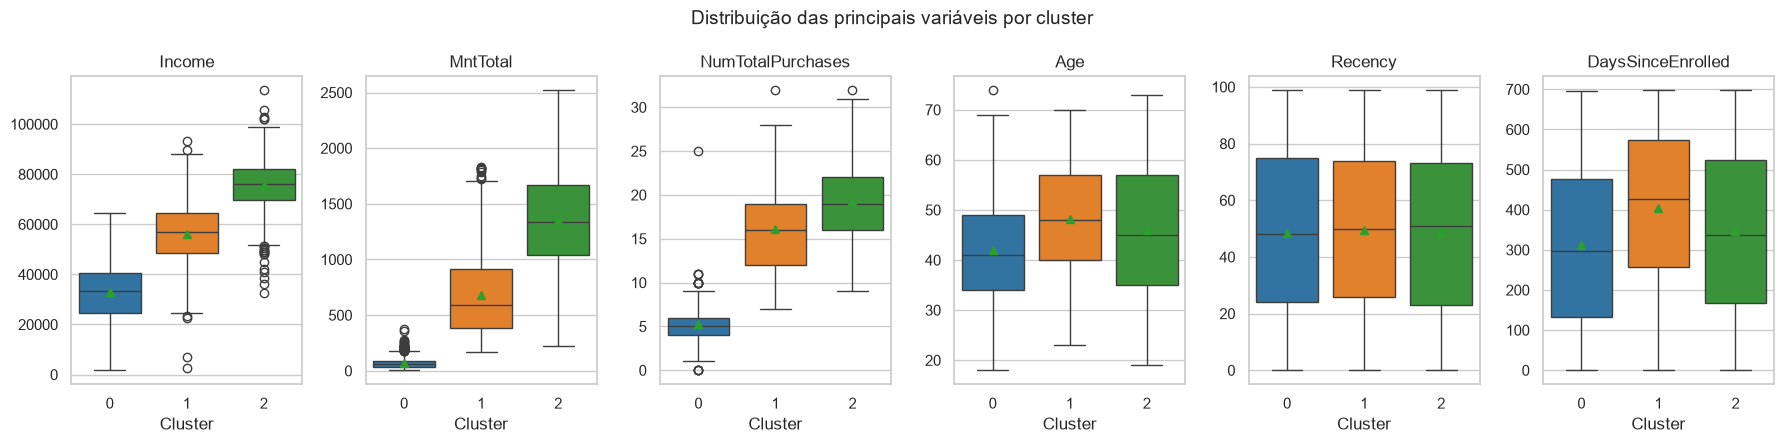

In [8]:
colunas_analise = ["Income", "MntTotal", "NumTotalPurchases", "Age", "Recency", "DaysSinceEnrolled"]

fig, axs = plt.subplots(1, 6, figsize=(18, 4.5))

for ax, coluna in zip(axs, colunas_analise):
    sns.boxplot(data=df_clusters, x="Cluster", y=coluna, hue="Cluster", palette="tab10", legend=False, showmeans=True, ax=ax)
    ax.set_title(coluna)
    ax.set_ylabel("")

fig.suptitle("Distribuição das principais variáveis por cluster", fontsize=14)
plt.tight_layout()
salvar_figura(fig, "perfil_clusters.png")
plt.show()

A **renda** e o **gasto total** separam muito bem os três clusters, com pouca sobreposição entre as caixas.
O número de compras acompanha o gasto. **Idade** e **recência** quase não diferenciam os grupos; o cluster 1
tem clientes um pouco mais velhos e há mais tempo na base. A segmentação foi guiada principalmente pelo poder
de compra e pela composição familiar, como mostra a próxima seção.

### 7.2 Variáveis categóricas

Duas funções de [`src/graficos.py`](src/graficos.py) ajudam a comparar proporções:

- **`plot_percentual_por_cluster`**: cada barra é um cluster e soma 100%. Responde "como é composto o cluster X?"
  (por exemplo, quantos por cento dos clientes do cluster têm filhos).
- **`plot_percentual_cluster_por_coluna`**: cada barra é uma categoria e soma 100%. Responde "em que clusters estão
  os clientes da categoria Y?" (por exemplo, onde estão os clientes que aceitaram três campanhas).

Ambas usam barras empilhadas normalizadas (`multiple="fill"` do seaborn), o que permite comparar grupos de
tamanhos diferentes.

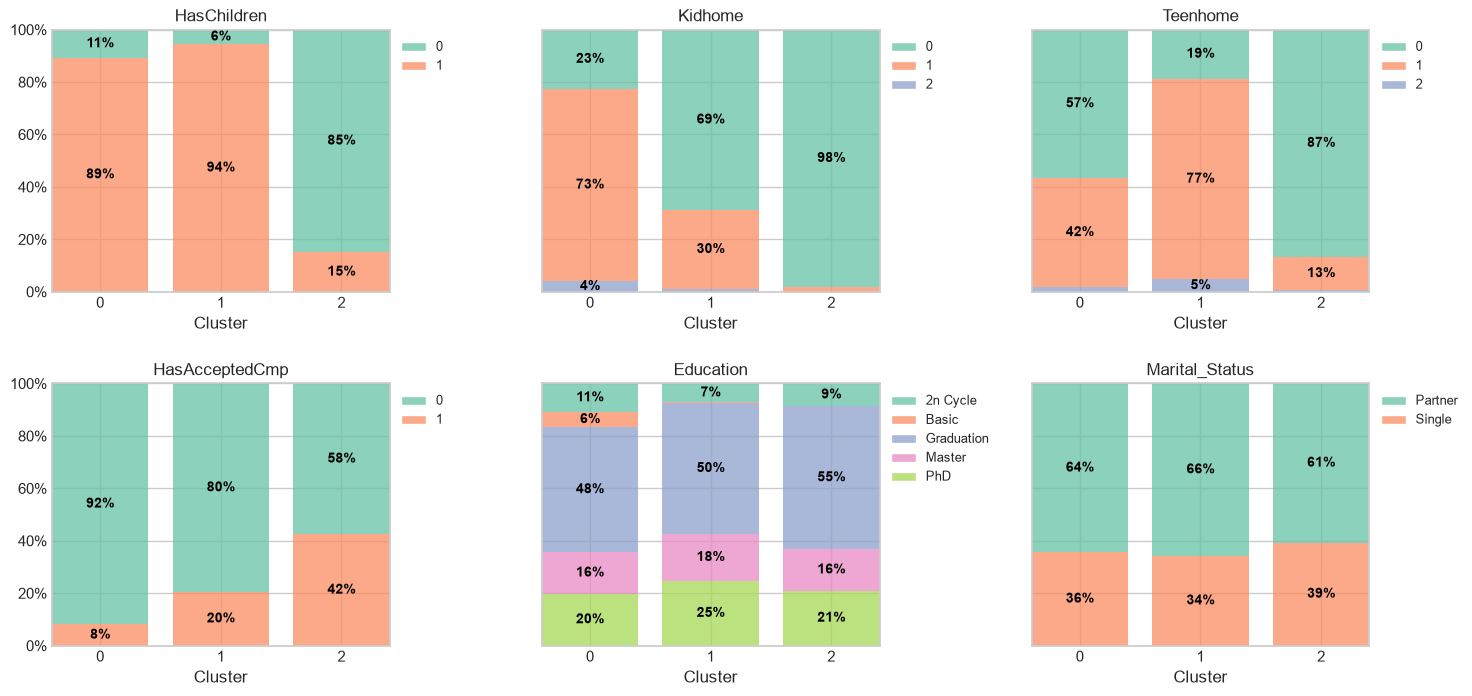

In [9]:
plot_percentual_por_cluster(
    df_clusters,
    ["HasChildren", "Kidhome", "Teenhome", "HasAcceptedCmp", "Education", "Marital_Status"],
    figsize=(17, 8),
    nome_arquivo="composicao_clusters.png",
)

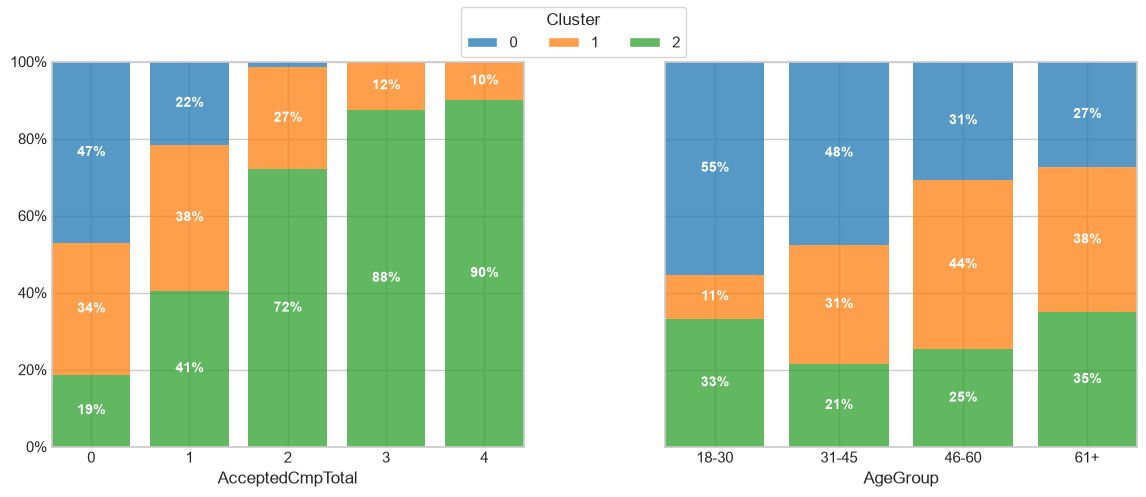

In [10]:
plot_percentual_cluster_por_coluna(
    df_clusters,
    ["AcceptedCmpTotal", "AgeGroup"],
    linhas_colunas=(1, 2),
    figsize=(14, 5),
)

In [11]:
resumo_clusters = df_clusters.groupby("Cluster").agg(
    clientes=("Income", "size"),
    renda_mediana=("Income", "median"),
    gasto_total_mediano=("MntTotal", "median"),
    gasto_vinhos_mediano=("MntWines", "median"),
    compras_mediana=("NumTotalPurchases", "median"),
    compras_catalogo_mediana=("NumCatalogPurchases", "median"),
    compras_desconto_mediana=("NumDealsPurchases", "median"),
    visitas_site_mes_mediana=("NumWebVisitsMonth", "median"),
    pct_com_filhos=("HasChildren", "mean"),
    pct_com_criancas=("Kidhome", lambda s: (s > 0).mean()),
    pct_com_adolescentes=("Teenhome", lambda s: (s > 0).mean()),
    pct_ja_aceitou_campanha=("HasAcceptedCmp", "mean"),
    idade_mediana=("Age", "median"),
    dias_cadastro_mediana=("DaysSinceEnrolled", "median"),
)

resumo_clusters.T.round(2)

Cluster,0,1,2
clientes,819.00,685.00,519.00
renda_mediana,33228.00,56937.00,76234.00
gasto_total_mediano,57.00,587.00,1336.00
gasto_vinhos_mediano,16.00,327.00,562.00
compras_mediana,5.00,16.00,19.00
compras_catalogo_mediana,0.00,2.00,6.00
compras_desconto_mediana,2.00,3.00,1.00
visitas_site_mes_mediana,7.00,6.00,2.00
pct_com_filhos,0.89,0.94,0.15
pct_com_criancas,0.77,0.31,0.02


## 8. Visualização com PCA

Os clientes estão descritos por 62 colunas depois do pré-processamento, e não dá para desenhar 62 dimensões.
A **análise de componentes principais (PCA)** cria novas variáveis, os componentes, que são combinações lineares
das colunas originais, ordenadas pela quantidade de variação dos dados que cada uma explica. Projetando os
clientes nos dois primeiros componentes, temos um "mapa" em 2D em que clientes parecidos ficam próximos.

A redução tem custo: parte da informação se perde. Por isso o PCA é usado aqui **só para visualizar**; a
segmentação continua sendo a do K-Means nas 62 colunas.

In [12]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)

df_pca = pd.DataFrame(
    pca.fit_transform(X_transformado),
    columns=["Componente 1", "Componente 2"],
    index=X_transformado.index,
)

print(f"Variância explicada: {pca.explained_variance_ratio_.round(3)} (total de {pca.explained_variance_ratio_.sum():.0%})")

# variáveis com maior peso em cada componente
cargas = pd.DataFrame(pca.components_.T, index=X_transformado.columns, columns=df_pca.columns)
for componente in cargas.columns:
    principais = cargas[componente].abs().sort_values(ascending=False).head(6).index
    print(f"\n{componente}:")
    print(cargas.loc[principais, componente].round(2).to_string())

Variância explicada: [0.472 0.098] (total de 57%)

Componente 1:
power__MntTotal               0.31
power__MntRegularProds        0.30
power__NumTotalPurchases      0.29
power__MntMeatProducts        0.29
power__NumCatalogPurchases    0.28
power__MntWines               0.28

Componente 2:
power__NumDealsPurchases    0.57
power__NumWebVisitsMonth    0.34
power__NumWebPurchases      0.31
one_hot__Teenhome_0        -0.23
one_hot__Teenhome_1         0.22
standard__Age               0.21


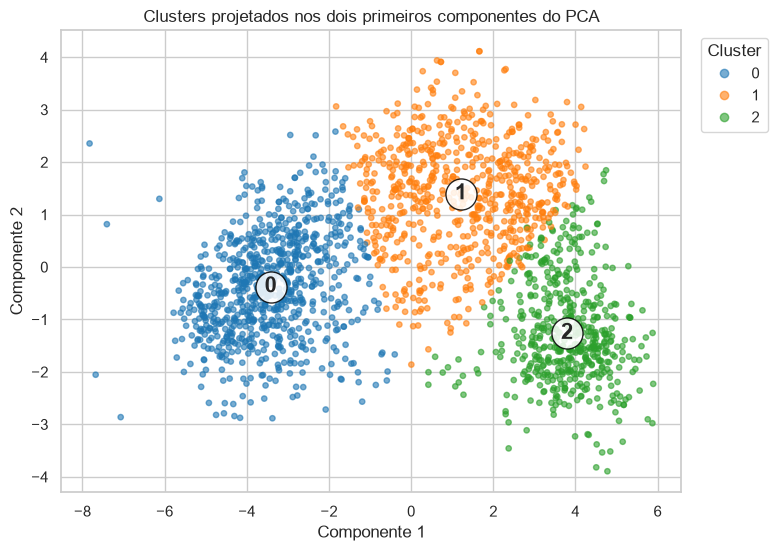

In [13]:
# como o PCA é linear, o centroide de cada cluster no plano é a média dos seus pontos projetados
centroides_pca = df_pca.groupby(df_clusters["Cluster"]).mean().values

plot_clusters_2d(
    df_pca,
    df_pca.columns,
    centroides=centroides_pca,
    coluna_clusters=df_clusters["Cluster"],
    titulo="Clusters projetados nos dois primeiros componentes do PCA",
    nome_arquivo="clusters_pca.png",
)

Os dois primeiros componentes explicam 57% da variação dos dados. O **componente 1** é, na prática, um eixo de
poder de compra: os maiores pesos são de gastos e quantidade de compras. Os três clusters aparecem como faixas
bem definidas ao longo desse eixo, com pouca sobreposição.

Para uma apresentação a públicos não técnicos, vale nomear os eixos de forma intuitiva ("poder de compra" no
eixo horizontal) e explicar o gráfico como um mapa de semelhança, sem entrar no cálculo dos componentes.

**Estabilidade da segmentação:** se o K-Means for aplicado sobre os dois componentes do PCA, em vez das
62 colunas, os grupos praticamente coincidem:

In [14]:
pipeline_pca = Pipeline(
    [
        ("preprocessamento", preprocessamento),
        ("pca", PCA(n_components=2, random_state=RANDOM_STATE)),
        ("clustering", KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)),
    ]
)
pipeline_pca.fit(X)

concordancia = adjusted_rand_score(pipeline_clusters["clustering"].labels_, pipeline_pca["clustering"].labels_)
print(f"Índice de Rand ajustado entre as duas segmentações: {concordancia:.2f} (1 = idênticas)")

Índice de Rand ajustado entre as duas segmentações: 0.94 (1 = idênticas)


## 9. Descrição dos clusters

### 9.1 Descrição técnica

Resumo com base nas tabelas e gráficos acima (valores medianos):

| | Cluster 0 | Cluster 1 | Cluster 2 |
|---|---|---|---|
| Clientes | 819 (40%) | 685 (34%) | 519 (26%) |
| Renda | 33 mil | 57 mil | 76 mil |
| Gasto total em 2 anos | 57 MU | 587 MU | 1.336 MU |
| Compras (total / catálogo / com desconto) | 5 / 0 / 2 | 16 / 2 / 3 | 19 / 6 / 1 |
| Visitas ao site por mês | 7 | 6 | 2 |
| Têm filhos | 89% (77% com crianças) | 94% (81% com adolescentes) | 15% |
| Já aceitaram alguma campanha | 8% | 20% | 42% |
| Idade | 41 anos | 48 anos | 45 anos |
| Tempo de cadastro | 297 dias | 426 dias | 337 dias |

- **Cluster 0:** menor renda e gasto muito baixo, com poucas compras em qualquer canal. É o grupo que mais visita
  o site, mas quase não compra por ele. A maioria tem crianças pequenas. Reúne quase todos os clientes com
  escolaridade "Basic" e quase não aceita campanhas.
- **Cluster 1:** renda e gasto intermediários. Quase todos têm filhos, principalmente adolescentes. São os clientes
  mais velhos e há mais tempo na base, e os que mais compram com desconto.
- **Cluster 2:** maior renda e maior gasto, concentrado em vinhos e carnes. Compram muito pelo catálogo e pouco com
  desconto, e visitam pouco o site. A grande maioria não tem filhos. É o grupo mais engajado com marketing:
  72% dos clientes que aceitaram duas campanhas e cerca de 90% dos que aceitaram três ou quatro estão aqui.
- **Estado civil e faixa etária não diferenciam bem os clusters**, o que confirma o que a análise exploratória
  já indicava.

### 9.2 Descrição para o negócio

Para apresentar a segmentação a quem não é da área técnica, damos um nome a cada grupo:

- 🟦 **Cluster 0 · "Famílias jovens com orçamento apertado" (40% dos clientes).** Renda baixa, filhos pequenos e
  pouco gasto. Navegam bastante no site, mas compram pouco. Raramente respondem a campanhas.
- 🟧 **Cluster 1 · "Famílias estabelecidas" (34%).** Renda média, filhos adolescentes e clientes antigos.
  Gastam de forma moderada e são os mais atraídos por descontos.
- 🟩 **Cluster 2 · "Clientes de alto valor" (26%).** Renda alta, geralmente sem filhos, gastam mais que todos,
  principalmente com vinhos e carnes, e preferem o catálogo. São os que mais respondem a campanhas.

## 10. Como cada cluster respondeu à campanha piloto

Com a segmentação pronta, trazemos `Response` de volta **apenas para descrever** os grupos. Ela não participou
da formação dos clusters.

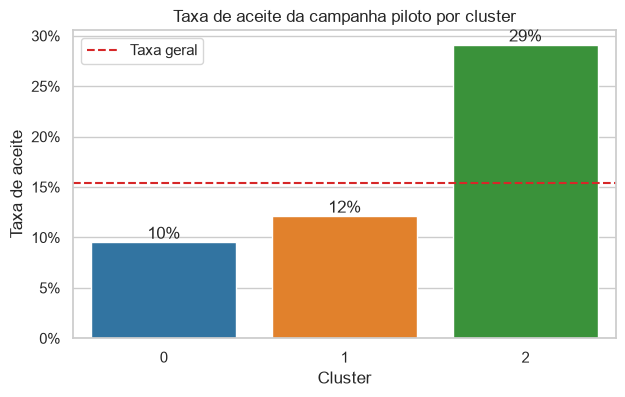

,clientes,aceites,taxa_aceite,pct_da_base,pct_dos_aceites
Cluster,,,,,
0,819,78,9.5%,40%,25%
1,685,83,12.1%,34%,27%
2,519,151,29.1%,26%,48%


In [15]:
resposta_por_cluster = df_clusters.groupby("Cluster").agg(
    clientes=("Response", "size"),
    aceites=("Response", "sum"),
    taxa_aceite=("Response", "mean"),
)
resposta_por_cluster["pct_da_base"] = resposta_por_cluster["clientes"] / resposta_por_cluster["clientes"].sum()
resposta_por_cluster["pct_dos_aceites"] = resposta_por_cluster["aceites"] / resposta_por_cluster["aceites"].sum()

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    x=resposta_por_cluster.index,
    y=resposta_por_cluster["taxa_aceite"],
    hue=resposta_por_cluster.index,
    palette="tab10",
    legend=False,
    ax=ax,
)
ax.axhline(df_clusters["Response"].mean(), color="tab:red", linestyle="--", label="Taxa geral")
for barras in ax.containers:
    ax.bar_label(barras, fmt=lambda v: f"{v:.0%}")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylabel("Taxa de aceite")
ax.set_title("Taxa de aceite da campanha piloto por cluster")
ax.legend()
salvar_figura(fig, "aceite_por_cluster.png")
plt.show()

resposta_por_cluster.style.format(
    {"taxa_aceite": "{:.1%}", "pct_da_base": "{:.0%}", "pct_dos_aceites": "{:.0%}"}
)

- **O cluster 2 aceita a oferta duas vezes mais que a média** (29% contra 15%) e concentra **48% dos aceites
  com só 26% da base**.
- Os clusters 0 e 1 ficam em 10% e 12%, abaixo da média.

**A segmentação sozinha não resolve o problema financeiro.** Com custo de 3 MU por contato e receita de 11 MU por
aceite, uma campanha só se paga se mais de **3/11 ≈ 27%** dos contatados aceitarem. Mesmo o melhor cluster
(29%) fica pouco acima desse ponto de equilíbrio:

In [16]:
def lucro(clientes):
    return RECEITA_ACEITE * clientes["Response"].sum() - CUSTO_CONTATO * len(clientes)

print(f"Contatar todos os clientes:      {lucro(df_clusters):>6,.0f} MU")
print(f"Contatar só o cluster 2:         {lucro(df_clusters.query('Cluster == 2')):>6,.0f} MU")
print(f"Contatar os clusters 1 e 2:      {lucro(df_clusters.query('Cluster >= 1')):>6,.0f} MU")

Contatar todos os clientes:      -2,637 MU
Contatar só o cluster 2:            104 MU
Contatar os clusters 1 e 2:      -1,038 MU


Contatar só o cluster 2 transformaria o prejuízo em um lucro pequeno. Para ir além, é preciso escolher os clientes
individualmente dentro e fora dos clusters, que é o papel do modelo de classificação.

## 11. Recomendações para o marketing

1. **Priorizar o cluster 2 na campanha do gadget, mas escolhendo os clientes um a um.** A taxa do cluster fica
   perto do ponto de equilíbrio, então é o modelo de propensão da [Parte 3](03_modelo_propensao_e_lucro.ipynb),
   que estima a probabilidade de cada cliente, que torna a campanha lucrativa.
2. **Cluster 2 (alto valor):** usar o **catálogo**, canal que esse grupo mais usa, e ofertas premium associadas a
   vinhos e carnes, onde está o maior gasto. Descontos não são necessários para esse público.
3. **Cluster 1 (famílias estabelecidas):** ofertas com **desconto** ou condições de pagamento, que é o que mais
   atrai esse grupo, e ações de fidelidade para clientes antigos.
4. **Cluster 0 (orçamento apertado):** **evitar ligações**, porque com 10% de aceite cada contato telefônico dá
   prejuízo. Usar canais digitais de custo baixo (e-mail, app, site) e investigar por que esses clientes visitam
   tanto o site e compram tão pouco: há espaço para melhorar a conversão.

## 12. Base com os clusters

Salvamos a base com o rótulo de cluster para consulta. **O rótulo não é usado como variável do modelo da
Parte 3**: o K-Means foi ajustado em toda a base, e usá-lo como feature levaria informação dos dados de
validação para o treino. O cluster serve para descrever os clientes que o modelo selecionar.

In [17]:
df_clusters.to_parquet(DADOS_CLUSTERIZADOS)